# Lab 9A — Neural Audio Codecs and Token-Based Generation

**AIML ZG527 — Audio Analysis**

**Authored by**: Seetha Parameswaran, BITS Pilani WILP

---

## What this lab is about

The module argued that modern audio generation rests on one trick: **turn audio into a short sequence of integers**, then generate those integers with an ordinary language model. This lab makes that trick concrete, end to end.

We first take a real recording and pass it through a **neural audio codec** (EnCodec) — a *learned tokenizer* for audio. We inspect the integer tokens it produces, hear what happens as we throw codebooks away, and measure the **reconstruction ceiling** it imposes on everything downstream. We then generate new music with **MusicGen**, a transformer that predicts exactly these tokens, and finally score the results with **CLAP**.

## Learning outcomes

By the end of this notebook you will be able to:

1. **Encode audio into discrete tokens** with EnCodec, and read off the token grid (codebooks × time) as an array of integers.
2. **Explain and hear Residual Vector Quantization** as a coarse-to-fine scheme, by decoding with 1, 2, 3, and 4 codebooks and listening to quality degrade gracefully.
3. **Compute the compression ratio and bitrate** of a codec, and relate them to the sequence length a transformer must model.
4. **Articulate the reconstruction ceiling** — why no token-based generator can ever sound better than the codec's own reconstruction of real audio — and demonstrate it.
5. **Generate audio with MusicGen** from a text prompt, and control it with the classifier-free guidance dial.
6. **Evaluate generation with CLAP**, scoring audio against matched and mismatched prompts, and reason about why a reference-free metric is both necessary and circular.

## Dataset

**TinySOL** — a library of isolated instrument notes, each a single sustained pitch played by one instrument (strings, brass, woodwinds, and more).

- **Structure:** nested directories, e.g. `Brass/Bass_Tuba/ordinario/*.wav`. We use `os.walk` to find files, since they are not flat under the root.
- **Why TinySOL here:** the codec and MusicGen both operate in the *music* domain, so clean, single-source instrument notes are the natural input for demonstrating encoding, reconstruction, and generation. Clips are short and harmonically simple, which makes codec artefacts easy to hear.

## Environment

**CPU-only.** All models run without a GPU, but MusicGen generation is slow (several minutes per clip). This notebook is **pre-run**, and its outputs are saved below — you are meant to read and listen, not execute it live.

> `audiocraft` is deliberately **not** used — it requires CUDA. MusicGen is accessed through HuggingFace `transformers` instead, which runs on CPU.

## 0. Setup

In [ ]:
# One-time install (uncomment if needed).
# NOTE: `audiocraft` is NOT used -- it requires CUDA.
# MusicGen and AudioGen are accessed through HuggingFace transformers instead.
#
# !pip install "numpy==1.26.4"
# !pip install torch --index-url https://download.pytorch.org/whl/cpu
# !pip install transformers librosa soundfile matplotlib

In [1]:
import os
import numpy as np
import torch
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

torch.set_num_threads(os.cpu_count())
DEVICE = "cpu"

print("torch :", torch.__version__)
print("numpy :", np.__version__)
print("device:", DEVICE)

torch : 2.4.1+cu121
numpy : 1.24.4
device: cpu


In [2]:
# ---- Paths (edit to match the lab machine) ----
TINYSOL_ROOT = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/TinySOL"

# The shared prompt. The SAME prompt is used in Lab 6E with a diffusion model,
# so the two paradigms can be compared on identical input.
SHARED_PROMPT = "a dog barking while a car passes by"

SR = 32000   # MusicGen / EnCodec-32k sample rate

## 1. Load an audio clip

TinySOL is nested: `Brass/Bass_Tuba/ordinario/*.wav`. We walk the tree to find files.

In [3]:
def find_tinysol_files(root, limit=None):
    """TinySOL has a nested directory structure, so os.walk is required."""
    files = []
    for dirpath, _, filenames in os.walk(root):
        for fn in filenames:
            if fn.lower().endswith(".wav"):
                files.append(os.path.join(dirpath, fn))
                if limit and len(files) >= limit:
                    return sorted(files)
    return sorted(files)

wav_files = find_tinysol_files(TINYSOL_ROOT)
print(f"Found {len(wav_files)} wav files")

for f in wav_files[:5]:
    print("  ", os.path.relpath(f, TINYSOL_ROOT))

Found 2913 wav files
   Brass/Bass_Tuba/ordinario/BTb-ord-A#1-ff-N-T30d.wav
   Brass/Bass_Tuba/ordinario/BTb-ord-A#1-mf-N-N.wav
   Brass/Bass_Tuba/ordinario/BTb-ord-A#1-pp-N-N.wav
   Brass/Bass_Tuba/ordinario/BTb-ord-A#2-ff-N-T19u.wav
   Brass/Bass_Tuba/ordinario/BTb-ord-A#2-mf-N-T29u.wav


In [4]:
# Pick one clip to work with throughout Parts 1-3.
CLIP_PATH = wav_files[0]
print("Using:", os.path.relpath(CLIP_PATH, TINYSOL_ROOT))

audio, _ = librosa.load(CLIP_PATH, sr=SR, mono=True)

# EnCodec is happier with a few seconds; pad or trim to 3 s.
TARGET_LEN = SR * 3
if len(audio) < TARGET_LEN:
    audio = np.pad(audio, (0, TARGET_LEN - len(audio)))
audio = audio[:TARGET_LEN]

print(f"duration: {len(audio)/SR:.2f} s   samples: {len(audio)}")
display(Audio(audio, rate=SR))

Using: Brass/Bass_Tuba/ordinario/BTb-ord-A#1-ff-N-T30d.wav
duration: 3.00 s   samples: 96000


## 2. EnCodec: audio in, integers out

Load the codec MusicGen actually uses. Note the configuration:

- **32 kHz** sample rate
- **50 frames per second** (a stride of 640)
- **4 codebooks**, each with 2048 entries

So one second of audio becomes `50 x 4 = 200` integers.

In [5]:
from transformers import EncodecModel, AutoProcessor

codec = EncodecModel.from_pretrained("facebook/encodec_32khz").to(DEVICE).eval()
codec_proc = AutoProcessor.from_pretrained("facebook/encodec_32khz")

cfg = codec.config
print("sampling_rate      :", cfg.sampling_rate)
print("frame rate (Hz)    :", cfg.frame_rate)
print("codebook size      :", cfg.codebook_size)
print("num quantizers     :", cfg.num_quantizers)

2026-07-16 17:38:46.511108: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-16 17:38:46.511134: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/transformers/models/encodec/modeling_encodec.py:124: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("padding_total", torch.tensor(kernel_size - stride, dtype=torch.int64), persistent=False)


sampling_rate      : 32000
frame rate (Hz)    : 50
codebook size      : 2048
num quantizers     : 4


In [6]:
# ---- ENCODE ----
inputs = codec_proc(raw_audio=audio, sampling_rate=SR, return_tensors="pt")

with torch.no_grad():
    enc = codec.encode(inputs["input_values"], inputs["padding_mask"])

codes = enc.audio_codes          # (batch, chunks, n_codebooks, n_frames)
tokens = codes[0, 0]             # (n_codebooks, n_frames)

print("token array shape :", tuple(tokens.shape), "  <- (codebooks, time)")
print("dtype             :", tokens.dtype)
print("value range       :", int(tokens.min()), "to", int(tokens.max()))
print()
print("THIS IS THE WHOLE POINT: the audio is now a grid of INTEGERS.")
print()
print("First 12 timesteps, all 4 codebooks:")
print(tokens[:, :12].numpy())

token array shape : (4, 150)   <- (codebooks, time)
dtype             : torch.int64
value range       : 8 to 2044

THIS IS THE WHOLE POINT: the audio is now a grid of INTEGERS.

First 12 timesteps, all 4 codebooks:
[[ 753   83   66 1958 1667  985 1629 1828 1908  985 1871  793]
 [1534  756 1174 1886 1460  888 1941 1886 1448 2042 1779 1392]
 [1793 2042  790  552  305  305  601  289 1531 1858 1027 1938]
 [1344   55 1568   92  480 1568  286  224  103 1019  480 1019]]


In [7]:
# How much did we compress?
n_cb, n_frames = tokens.shape
bits_per_code = int(np.log2(cfg.codebook_size))

n_tokens  = n_cb * n_frames
bitrate   = (n_frames / (len(audio)/SR)) * n_cb * bits_per_code

print(f"raw samples      : {len(audio):>8,}")
print(f"codec tokens     : {n_tokens:>8,}")
print(f"compression      : {len(audio)/n_tokens:>8.1f}x  (samples per token)")
print()
print(f"bits per code    : {bits_per_code}")
print(f"bitrate          : {bitrate/1000:.1f} kbps   (MP3 transparent is ~128 kbps)")

raw samples      :   96,000
codec tokens     :      600
compression      :    160.0x  (samples per token)

bits per code    : 11
bitrate          : 2.2 kbps   (MP3 transparent is ~128 kbps)


### Visualise the token grid

Two axes: **time** (across) and **codebook depth** (down). Codebook 1 carries the gross
structure; codebook 4 carries fine detail. They are *not* independent — this is exactly
the grid that MusicGen's **delay pattern** has to flatten into one sequence.

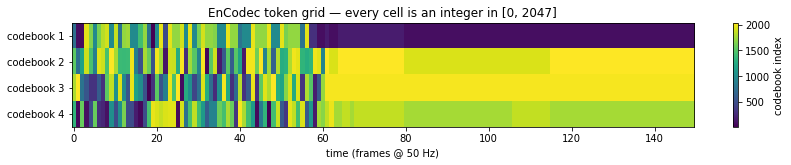

In [8]:
fig, ax = plt.subplots(figsize=(12, 2.4))
im = ax.imshow(tokens.numpy(), aspect="auto", interpolation="nearest", cmap="viridis")
ax.set_yticks(range(n_cb))
ax.set_yticklabels([f"codebook {i+1}" for i in range(n_cb)])
ax.set_xlabel("time (frames @ 50 Hz)")
ax.set_title("EnCodec token grid — every cell is an integer in [0, 2047]")
plt.colorbar(im, ax=ax, label="codebook index")
plt.tight_layout()
plt.show()

## 3. Round-trip: decode the tokens back to audio

The decoder is **GAN-trained** — exactly the role Section 3 of the deck predicted for GANs.

In [9]:
with torch.no_grad():
    recon = codec.decode(enc.audio_codes, [None], inputs["padding_mask"])[0]

recon = recon[0, 0].cpu().numpy()[:len(audio)]

print("ORIGINAL")
display(Audio(audio, rate=SR))
print("RECONSTRUCTED from 4 codebooks (2.2 kbps)")
display(Audio(recon, rate=SR))

ORIGINAL


RECONSTRUCTED from 4 codebooks (2.2 kbps)


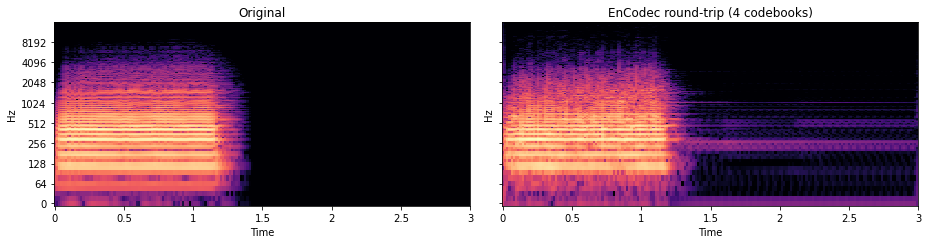

In [10]:
# Compare spectrograms.
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax, sig, title in zip(axes, [audio, recon], ["Original", "EnCodec round-trip (4 codebooks)"]):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(sig)), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="log", ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 4. Residual VQ is coarse-to-fine — hear it

Decode using only the **first N codebooks**, discarding the rest.

- Codebook 1 alone: the gross structure. Recognisable, but crude.
- Adding codebooks: progressively finer detail.

This is the **scalable bitrate** property. Quality degrades *gracefully*, not catastrophically.

In [11]:
def decode_n_codebooks(n):
    """Decode using only the first n codebooks (zeroing the rest is NOT the same --
    we must actually slice, so the decoder sums fewer residuals)."""
    partial = enc.audio_codes[:, :, :n, :]
    with torch.no_grad():
        out = codec.decode(partial, [None], inputs["padding_mask"])[0]
    return out[0, 0].cpu().numpy()[:len(audio)]

for n in [1, 2, 3, 4]:
    br = (n_frames / (len(audio)/SR)) * n * bits_per_code / 1000
    print(f"--- {n} codebook(s)   ~{br:.1f} kbps ---")
    display(Audio(decode_n_codebooks(n), rate=SR))

--- 1 codebook(s)   ~0.6 kbps ---


--- 2 codebook(s)   ~1.1 kbps ---


--- 3 codebook(s)   ~1.6 kbps ---


--- 4 codebook(s)   ~2.2 kbps ---


## 5. The reconstruction ceiling

**This is the most important cell in the notebook.**

MusicGen does not generate audio. It generates *tokens*, which are then decoded by this
same EnCodec decoder.

So the clip below — a **real** recording, encoded and decoded at MusicGen's exact
4-codebook setting — is the **best MusicGen could ever possibly sound.**

No amount of scaling the transformer changes this. The codec sets the ceiling.

In [12]:
ceiling = decode_n_codebooks(4)

print("A REAL recording, passed through MusicGen's codec.")
print("This is the quality ceiling for every token-LM generator.\n")
display(Audio(ceiling, rate=SR))

# Quantify the loss.
noise = audio - ceiling
snr = 10 * np.log10(np.sum(audio**2) / (np.sum(noise**2) + 1e-12))
print(f"Reconstruction SNR: {snr:.1f} dB")

A REAL recording, passed through MusicGen's codec.
This is the quality ceiling for every token-LM generator.



Reconstruction SNR: 7.4 dB


## 6. MusicGen — a transformer over codec tokens

Now we generate. MusicGen is a **decoder-only transformer** that predicts EnCodec tokens,
conditioned on a text prompt via cross-attention to a frozen T5 encoder.

The pipeline is exactly the one from the slides:

`text -> T5 -> transformer LM -> tokens -> EnCodec decoder -> audio`

**CPU warning:** this takes several minutes. Pre-run, do not execute live.

In [13]:
from transformers import MusicgenForConditionalGeneration, AutoProcessor as MGProcessor

mg_proc  = MGProcessor.from_pretrained("facebook/musicgen-small")
musicgen = MusicgenForConditionalGeneration.from_pretrained(
    "facebook/musicgen-small"
).to(DEVICE).eval()

MG_SR = musicgen.config.audio_encoder.sampling_rate
print("MusicGen sample rate:", MG_SR)

# 256 tokens ~= 5 seconds at 50 Hz.
MAX_NEW_TOKENS = 256

model.safetensors:  28%|##8       | 671M/2.36G [00:00<?, ?B/s]

Config of the text_encoder: <class 'transformers.models.t5.modeling_t5.T5EncoderModel'> is overwritten by shared text_encoder config: T5Config {
  "_name_or_path": "t5-base",
  "architectures": [
    "T5ForConditionalGeneration"
  ],
  "classifier_dropout": 0.0,
  "d_ff": 3072,
  "d_kv": 64,
  "d_model": 768,
  "decoder_start_token_id": 0,
  "dense_act_fn": "relu",
  "dropout_rate": 0.1,
  "eos_token_id": 1,
  "feed_forward_proj": "relu",
  "initializer_factor": 1.0,
  "is_encoder_decoder": true,
  "is_gated_act": false,
  "layer_norm_epsilon": 1e-06,
  "model_type": "t5",
  "n_positions": 512,
  "num_decoder_layers": 12,
  "num_heads": 12,
  "num_layers": 12,
  "output_past": true,
  "pad_token_id": 0,
  "relative_attention_max_distance": 128,
  "relative_attention_num_buckets": 32,
  "task_specific_params": {
    "summarization": {
      "early_stopping": true,
      "length_penalty": 2.0,
      "max_length": 200,
      "min_length": 30,
      "no_repeat_ngram_size": 3,
      "num_be

generation_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

MusicGen sample rate: 32000


In [14]:
MUSIC_PROMPTS = [
    "a slow melancholic solo cello piece",
    "an upbeat lo-fi hip hop track with a jazzy piano",
]

mg_inputs = mg_proc(text=MUSIC_PROMPTS, padding=True, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    mg_audio = musicgen.generate(
        **mg_inputs,
        do_sample=True,
        guidance_scale=3.0,      # classifier-free guidance: the prompt-adherence dial
        max_new_tokens=MAX_NEW_TOKENS,
    )

music_clips = {}
for prompt, wav in zip(MUSIC_PROMPTS, mg_audio):
    clip = wav[0].cpu().numpy()
    music_clips[prompt] = clip
    print(f'"{prompt}"')
    display(Audio(clip, rate=MG_SR))

`torch.nn.functional.scaled_dot_product_attention` does not support having an empty attention mask. Falling back to the manual attention implementation. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.Note that this probably happens because `guidance_scale>1` or because you used `get_unconditional_inputs`. See https://github.com/huggingface/transformers/issues/31189 for more information.


"a slow melancholic solo cello piece"


"an upbeat lo-fi hip hop track with a jazzy piano"


### The guidance dial

`guidance_scale` is **classifier-free guidance**. Turn it up for stronger prompt
adherence; turn it down for more diversity. Same prompt, three settings.

In [15]:
GUIDANCE_PROMPT = "an upbeat lo-fi hip hop track with a jazzy piano"
g_inputs = mg_proc(text=[GUIDANCE_PROMPT], padding=True, return_tensors="pt").to(DEVICE)

for g in [1.0, 3.0, 7.0]:
    with torch.no_grad():
        out = musicgen.generate(**g_inputs, do_sample=True,
                                guidance_scale=g, max_new_tokens=MAX_NEW_TOKENS)
    print(f"--- guidance_scale = {g} ---")
    display(Audio(out[0, 0].cpu().numpy(), rate=MG_SR))

--- guidance_scale = 1.0 ---


--- guidance_scale = 3.0 ---


--- guidance_scale = 7.0 ---


## 7. Evaluation with CLAP

Generation has **no reference** to compare against — a thousand different clips could all
be correct answers to one prompt.

So we ask a different question: **does the audio match the text?**

CLAP (Session 12) embeds text and audio into a *shared* space. Embed the prompt, embed the
generated clip, measure cosine similarity. The same model that powered *retrieval* now
grades *generation*.

In [16]:
from transformers import ClapModel, ClapProcessor

clap      = ClapModel.from_pretrained("laion/clap-htsat-unfused").to(DEVICE).eval()
clap_proc = ClapProcessor.from_pretrained("laion/clap-htsat-unfused")

CLAP_SR = 48000

def clap_score(waveform, sr, text):
    """Cosine similarity between a text prompt and an audio clip, in CLAP space."""
    wav = librosa.resample(waveform.astype(np.float32), orig_sr=sr, target_sr=CLAP_SR)

    a_in = clap_proc(audios=wav, sampling_rate=CLAP_SR, return_tensors="pt").to(DEVICE)
    t_in = clap_proc(text=[text], return_tensors="pt", padding=True).to(DEVICE)

    with torch.no_grad():
        ae = clap.get_audio_features(**a_in)
        te = clap.get_text_features(**t_in)

    ae = ae / ae.norm(dim=-1, keepdim=True)
    te = te / te.norm(dim=-1, keepdim=True)
    return float((ae @ te.T).item())

In [17]:
# Score each generated clip against its OWN prompt (should be high)
# and against a MISMATCHED prompt (should be low).
# If the metric cannot tell these apart, it is measuring nothing.

MISMATCH = "a solo violin playing a sad melody"

print(f"{'clip':<42} {'own prompt':>11} {'mismatched':>11}")

for prompt, clip in music_clips.items():
    own = clap_score(clip, MG_SR, prompt)
    mis = clap_score(clip, MG_SR, "a dog barking loudly")
    print(f"{prompt[:40]:<42} {own:>11.3f} {mis:>11.3f}")

clip                                        own prompt  mismatched
a slow melancholic solo cello piece              0.464      -0.080
an upbeat lo-fi hip hop track with a jaz         0.424      -0.065


In [18]:
# Sanity check: CLAP on REAL audio, not generated audio.
# The reconstruction-ceiling clip is a real instrument note.
print("Real TinySOL clip, scored against candidate descriptions:\n")
for desc in ["a brass instrument playing a single note",
             "a dog barking loudly",
             "an electric guitar solo"]:
    s = clap_score(audio, SR, desc)
    print(f"  {s:>6.3f}   {desc}")

Real TinySOL clip, scored against candidate descriptions:

   0.511   a brass instrument playing a single note
  -0.085   a dog barking loudly
  -0.141   an electric guitar solo


## What to take away

1. **Audio became integers.** That is the whole trick. A 3-second clip went from roughly 96,000 float samples to a `4 × 150` grid of integers — a reduction of over 150× in sequence length. Only *then* does a transformer become a practical way to generate audio.

2. **Residual VQ is coarse-to-fine, by design.** You heard quality degrade gracefully as codebooks were dropped: codebook 1 alone gave the gross structure, and each added codebook filled in detail. This is why a codec can offer a *scalable* bitrate from a single trained model.

3. **The codec sets the ceiling.** MusicGen can never sound better than the round-trip in Part 5, because it decodes *through* this same codec. If you want better generated audio, improving the **codec** may matter more than scaling the **transformer** — a genuinely useful engineering insight.

4. **Guidance is a control dial, not a quality knob.** Higher classifier-free guidance pushes the output to match the prompt more literally, at some cost to diversity. There is no single "best" setting — it depends on what you want.

5. **CLAP grades generation, but the grade is circular.** With no reference to compare against, we ask a proxy model whether the audio matches the text. That works — the matched/mismatched gap is real — but we are judging a generator with a model trained on the same kind of data. A generator tuned to please CLAP is not necessarily one that pleases a listener. **Always listen.**

---